# Cookie Cats A/B Test

Cookie Cats is a mobile puzzle game. At level 30 there is a gate where players have to wait or pay to continue. The company tested moving this gate to level 40.

Players were randomly split into two groups:
- gate_30: the gate stays at level 30
- gate_40: the gate moves to level 40

**Question: does moving the gate to level 40 make more players come back to the game?**

I used Python and SQL for this analysis.

## Loading the data

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

df = pd.read_csv("cookie_cats.csv")
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


Columns:
- userid: player id
- version: gate_30 or gate_40
- sum_gamerounds: number of rounds played in the first 14 days
- retention_1: did the player come back after 1 day
- retention_7: did the player come back after 7 days

In [2]:
print(df.isnull().sum())
print("duplicate players:", df["userid"].duplicated().sum())

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
duplicate players: 0


No missing values and no duplicate players.

In [3]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

One player played 49,854 rounds in 14 days. This looks like an error or a bot, but it does not affect retention, so I kept it.

## Comparing the two groups with SQL

In [4]:
df["retention_1"] = df["retention_1"].astype(int)
df["retention_7"] = df["retention_7"].astype(int)

conn = sqlite3.connect(":memory:")
df.to_sql("players", conn, index=False)

result = pd.read_sql("""
SELECT version,
       COUNT(*) AS players,
       SUM(retention_1) AS back_day_1,
       ROUND(AVG(retention_1) * 100, 2) AS day_1_pct,
       SUM(retention_7) AS back_day_7,
       ROUND(AVG(retention_7) * 100, 2) AS day_7_pct
FROM players
GROUP BY version
""", conn)

result

,version,players,back_day_1,day_1_pct,back_day_7,day_7_pct
0,gate_30,44700,20034,44.82,8502,19.02
1,gate_40,45489,20119,44.23,8279,18.20


The two groups are almost the same size (44,700 and 45,489). In the gate_40 group, a slightly lower percentage of players came back on day 1 and on day 7.

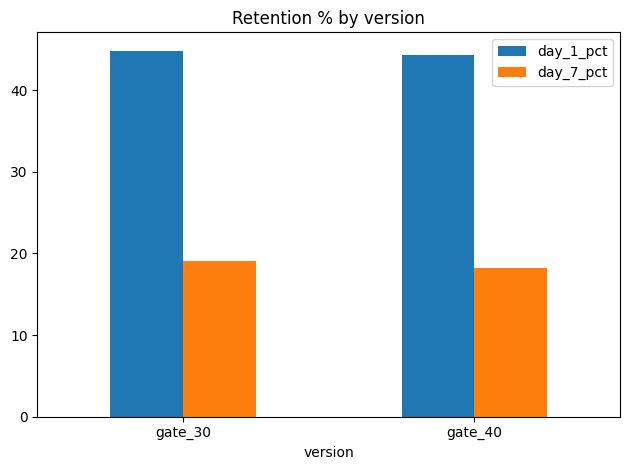

In [5]:
result.plot(x="version", y=["day_1_pct", "day_7_pct"], kind="bar", title="Retention % by version")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("retention.png")
plt.show()

### How many rounds do players play?

In [6]:
pd.read_sql("""
SELECT CASE
           WHEN sum_gamerounds = 0 THEN '0'
           WHEN sum_gamerounds < 30 THEN '1-29'
           WHEN sum_gamerounds < 100 THEN '30-99'
           ELSE '100+'
       END AS rounds,
       COUNT(*) AS players
FROM players
GROUP BY rounds
ORDER BY MIN(sum_gamerounds)
""", conn)

,rounds,players
0,0,3994
1,1-29,52926
2,30-99,20753
3,100+,12516


Almost 4,000 players installed the game and never played even one round.

## Is the difference real?

The difference in day 7 retention is small (19.02% vs 18.20%). To check if it is real or just by chance, I used a z-test for two proportions.

- If the p-value is less than 0.05, the difference is significant (not by chance).

In [7]:
gate30 = result[result["version"] == "gate_30"].iloc[0]
gate40 = result[result["version"] == "gate_40"].iloc[0]

for day in ["back_day_1", "back_day_7"]:
    z, p = proportions_ztest([gate30[day], gate40[day]], [gate30["players"], gate40["players"]])
    print(day, " p-value =", round(p, 4))

back_day_1  p-value = 0.0744
back_day_7  p-value = 0.0016


- Day 1: p-value = 0.074, more than 0.05, so the difference can be by chance.
- Day 7: p-value = 0.0016, less than 0.05, so the drop is real.

## Conclusion

When the gate was moved to level 40, day 7 retention went down from 19.02% to 18.20%, and the test shows this drop is not by chance.

**My recommendation is to keep the gate at level 30.**

Limitations:
- There is no revenue data, so I can't say how the change affects money.
- The data covers only 14 days.